# SE4042 · Lab 6 · Finite Element Methods — Python part
This notebook goes with **Part F** of the Lab 6 sheet. Work top to bottom (Runtime → Run all once you have filled the TODOs).

* **P1** — measure three different errors of the 1-D solver from Lecture 6 and find their rates.
* **P2** — run the 2-D L-shape solver (Listing 6.3 of Chapter 6) and measure the rate that the corner allows.
* **P3** — upload the VTK files you exported from **COEAI FEM Studio** and compute their energy errors exactly.

Only NumPy, SciPy and Matplotlib are needed; all three are pre-installed in Colab.

In [1]:
%pip install scipy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, scipy.sparse as sp, scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

## P1 · Three errors, three rates
$-u'' = \pi^2\sin\pi x$ on $(0,1)$, $u(0)=u(1)=0$; exact solution $u=\sin \pi x$. `fem_poisson_1d` is Listing 6.1 with one change: `nq` sets how many Gauss points integrate the load.

Complete `errors(n)` (TODO 1–4). The **energy error** is $\|u-u_h\|_E = \big(\int_0^1 (u'-u_h')^2\,dx\big)^{1/2}$.

In [3]:
def fem_poisson_1d(n, nq=2):
    """-u'' = pi^2 sin(pi x) on [0,1], u(0)=u(1)=0, n linear elements.
    nq = number of Gauss points used for the load vector."""
    h = 1.0 / n
    x = np.linspace(0, 1, n + 1)
    Nint = n - 1
    K = np.zeros((Nint, Nint))
    for e in range(n):
        Ke = np.array([[1, -1], [-1, 1]]) / h
        for a in range(2):
            for b in range(2):
                A, B = e + a - 1, e + b - 1
                if 0 <= A < Nint and 0 <= B < Nint:
                    K[A, B] += Ke[a, b]
    F = np.zeros(Nint)
    gp, gw = np.polynomial.legendre.leggauss(nq)
    src = lambda xx: np.pi**2 * np.sin(np.pi * xx)
    for e in range(n):
        xl, xr = x[e], x[e + 1]
        for g, w in zip(gp, gw):
            xg = 0.5*(xl + xr) + 0.5*h*g
            Na, Nb = (xr - xg)/h, (xg - xl)/h
            for Nval, idx in [(Na, e - 1), (Nb, e)]:
                if 0 <= idx < Nint:
                    F[idx] += w * 0.5*h * src(xg) * Nval
    u = np.zeros(n + 1)
    u[1:-1] = np.linalg.solve(K, F)
    return x, u

GX, GW = np.polynomial.legendre.leggauss(10)   # 10 Gauss points per element for the errors

def errors(n, nq=2):
    """Return (L2 error, energy error, max nodal error) for n elements."""
    x, u = fem_poisson_1d(n, nq)
    L2 = H1 = 0.0
    for e in range(n):
        h = x[e + 1] - x[e]
        xs, w = x[e] + (GX + 1)*h/2, GW*h/2       # Gauss points and weights in element e
        # TODO 1: u_h at the points xs (linear between u[e] and u[e+1])
        uh = u[e] + (u[e + 1] - u[e]) * (xs - x[e]) / h
        # TODO 2: the derivative of u_h on this element (a constant)
        duh = (u[e + 1] - u[e]) / h
        # TODO 3: add  w @ (u_h - u)^2  to L2  and  w @ (u_h' - u')^2  to H1
        #         exact solution u = sin(pi x), u' = pi cos(pi x)
        L2 += w @ (uh - np.sin(np.pi * xs))**2
        H1 += w @ (duh - np.pi * np.cos(np.pi * xs))**2
    # TODO 4: the largest error at the nodes
    nodal = np.abs(u - np.sin(np.pi * x)).max()
    return np.sqrt(L2), np.sqrt(H1), nodal

def slopes(ns, E):
    """Least-squares slope of log(error) against log(n), one per column of E."""
    return [np.polyfit(np.log(ns), np.log(E[:, j]), 1)[0] for j in range(E.shape[1])]


**P1a.** Run the convergence study. Record the table and the three slopes on your answer sheet.

In [4]:
ns = np.array([5, 10, 20, 50, 100])
E = np.array([errors(n) for n in ns])
for n, (a, b, c) in zip(ns, E):
    print(f'n = {n:4d}  L2 = {a:.3e}  energy = {b:.3e}  nodal = {c:.3e}')
print('slopes L2 / energy / nodal = %.2f / %.2f / %.2f' % tuple(slopes(ns, E)))

n =    5  L2 = 2.520e-02  energy = 4.003e-01  nodal = 1.051e-04
n =   10  L2 = 6.353e-03  energy = 2.011e-01  nodal = 6.800e-06
n =   20  L2 = 1.592e-03  energy = 1.007e-01  nodal = 4.233e-07
n =   50  L2 = 2.548e-04  energy = 4.029e-02  nodal = 1.083e-08
n =  100  L2 = 6.371e-05  energy = 2.015e-02  nodal = 6.765e-10
slopes L2 / energy / nodal = -2.00 / -1.00 / -3.99


**P1b.** Plot the three errors against $h = 1/n$ on log–log axes.

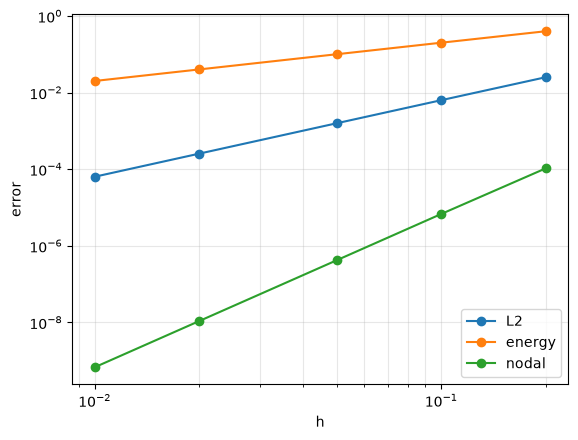

In [5]:
h = 1/ns
for j, lab in enumerate(['L2', 'energy', 'nodal']):
    plt.loglog(h, E[:, j], 'o-', label=lab)
plt.xlabel('h'); plt.ylabel('error'); plt.legend(); plt.grid(True, which='both', alpha=.3); plt.show()

**P1c.** Now integrate the load with **one** Gauss point (`nq=1`). Predict first: which of the three slopes will change?

In [6]:
E1 = np.array([errors(n, nq=1) for n in ns])
for n, (a, b, c) in zip(ns, E1):
    print(f'n = {n:4d}  L2 = {a:.3e}  energy = {b:.3e}  nodal = {c:.3e}')
print('slopes L2 / energy / nodal = %.2f / %.2f / %.2f' % tuple(slopes(ns, E1)))

n =    5  L2 = 3.613e-02  energy = 4.020e-01  nodal = 1.619e-02
n =   10  L2 = 9.085e-03  energy = 2.013e-01  nodal = 4.148e-03
n =   20  L2 = 2.275e-03  energy = 1.007e-01  nodal = 1.030e-03
n =   50  L2 = 3.641e-04  energy = 4.029e-02  nodal = 1.646e-04
n =  100  L2 = 9.103e-05  energy = 2.015e-02  nodal = 4.113e-05
slopes L2 / energy / nodal = -2.00 / -1.00 / -2.00


## P2 · The L-shape: the corner sets the rate
$-\nabla^2 u = 1$ on $[0,2]^2$ minus the top-right quarter, $u = 0$ on the whole boundary — the same problem you built in FEM Studio in Part C. Because $f=1$, the energy error can be computed exactly from the integral of $u_h$:  $\|u-u_h\|_E^2 = \int u\,dx - \int u_h\,dx$, with $\int u\,dx = 0.21407581$.

In [7]:
def lshape_p1(m):
    """-lap u = 1 on [0,2]^2 minus the top-right quarter, u = 0 on all edges."""
    N, h = 2*m, 1.0/m
    keep = lambda i, j: not (i >= m and j >= m)
    idx, P = {}, []
    for j in range(N + 1):
        for i in range(N + 1):
            if any(keep(a, b) for a in (i-1, i) for b in (j-1, j)
                   if 0 <= a < N and 0 <= b < N):
                idx[i, j] = len(P); P.append((i*h, j*h))
    P, T = np.array(P), []
    for j in range(N):
        for i in range(N):
            if keep(i, j):
                a, b = idx[i, j], idx[i+1, j]
                c, d = idx[i+1, j+1], idx[i, j+1]
                T += [(a, b, c), (a, c, d)]
    n = len(P); rows, cols, vals, F = [], [], [], np.zeros(n)
    for t in T:
        M = np.column_stack([np.ones(3), P[list(t)]])
        A = abs(np.linalg.det(M)) / 2
        G = np.linalg.inv(M)[1:]
        Ke = A * G.T @ G
        rows += [a for a in t for _ in t]; cols += list(t) * 3
        vals += list(Ke.ravel()); F[list(t)] += A / 3
    K = sp.csr_matrix((vals, (rows, cols)), shape=(n, n))
    x, y = P.T; eps = 1e-12
    bnd = (x < eps) | (y < eps) | (x > 2-eps) | (y > 2-eps) \
        | ((abs(x-1) < eps) & (y >= 1)) | ((abs(y-1) < eps) & (x >= 1))
    free, u = ~bnd, np.zeros(n)
    u[free] = spla.spsolve(K[free][:, free].tocsc(), F[free])
    return P, u, F @ u

REF = 0.21407581      # integral of the exact solution over the L-shape


**P2a.** Run the uniform refinement study and fit the slope of energy error against the number of nodes $N$ (in 2-D, $N \propto h^{-2}$).

In [8]:
res = []
for m in [4, 8, 16, 32, 64]:
    P, u, I = lshape_p1(m)
    res.append((len(P), np.sqrt(REF - I)))
    print(f'm = {m:3d}  nodes = {len(P):6d}  max u = {u.max():.4f}  int u = {I:.5f}  energy error = {np.sqrt(REF - I):.4f}')
N, e = np.array(res).T
# TODO 5: fit the slope of log(e) against log(N) over the last three meshes, and convert it to a slope against h
slope_N = np.polyfit(np.log(N[-3:]), np.log(e[-3:]), 1)[0]
print(f'slope vs N = {slope_N:.3f}   slope vs h = {-2 * slope_N:.3f}')

m =   4  nodes =     65  max u = 0.1372  int u = 0.18910  energy error = 0.1580
m =   8  nodes =    225  max u = 0.1459  int u = 0.20664  energy error = 0.0862
m =  16  nodes =    833  max u = 0.1481  int u = 0.21181  energy error = 0.0476
m =  32  nodes =   3201  max u = 0.1490  int u = 0.21335  energy error = 0.0269
m =  64  nodes =  12545  max u = 0.1493  int u = 0.21383  energy error = 0.0156
slope vs N = -0.412   slope vs h = 0.824


## P3 · Check FEM Studio's answers yourself
In FEM Studio, after each L-shape solve in Part C, use **Results → Export → VTK (ParaView)**. Upload the `.vtk` files here (folder icon on the left, or run the next cell), then compute $\int u_h$ and the exact energy error for each.

In [9]:
try:
    from google.colab import files
    uploaded = files.upload()          # choose your .vtk files
except ImportError:
    print('Not in Colab: copy the .vtk files next to this notebook instead.')

Not in Colab: copy the .vtk files next to this notebook instead.


In [10]:
def read_vtk(path):
    """Read a FEM Studio legacy-VTK export: points, cells, cell types, point field T or u."""
    L = open(path).read().split('\n'); i = 0; data = {}; mode = 'p'
    while i < len(L):
        s = L[i]
        if s.startswith('POINTS'):
            n = int(s.split()[1]); P = np.array([L[i+1+k].split() for k in range(n)], float)[:, :2]; i += n
        elif s.startswith('CELLS'):
            n = int(s.split()[1]); C = [list(map(int, L[i+1+k].split()))[1:] for k in range(n)]; i += n
        elif s.startswith('CELL_TYPES'):
            n = int(s.split()[1]); TY = [int(L[i+1+k]) for k in range(n)]; i += n
        elif s.startswith('POINT_DATA'): mode = 'p'
        elif s.startswith('CELL_DATA'): mode = 'c'
        elif s.startswith('SCALARS'):
            name = s.split()[1]; n = len(P) if mode == 'p' else len(C)
            data[(mode, name)] = np.array([float(L[i+2+k]) for k in range(n)]); i += n + 1
        i += 1
    return P, C, TY, data

# 6-point rule on the reference triangle (exact for degree 4)
_A, _B, _C, _D = 0.445948490915965, 0.108103018168070, 0.091576213509771, 0.816847572980459
QP = np.array([[_A, _A], [_A, _B], [_B, _A], [_C, _C], [_C, _D], [_D, _C]])
QW = np.array([0.223381589678011]*3 + [0.109951743655322]*3) / 2

def shape(cell_type, s, t):
    l1, l2, l3 = 1 - s - t, s, t
    if cell_type == 5:                       # VTK_TRIANGLE (T3)
        return np.array([l1, l2, l3])
    return np.array([l1*(2*l1-1), l2*(2*l2-1), l3*(2*l3-1), 4*l1*l2, 4*l2*l3, 4*l3*l1])  # 22: T6

def integral_from_vtk(path):
    P, C, TY, d = read_vtk(path)
    key = ('p', 'T') if ('p', 'T') in d else ('p', 'u')
    u, I = d[key], 0.0
    for c, ty in zip(C, TY):
        X = P[c[:3]]
        J = abs(np.linalg.det(np.array([X[1] - X[0], X[2] - X[0]])))
        for (s, t), w in zip(QP, QW):
            I += w * J * (shape(ty, s, t) @ u[c])
    return len(P), u.max(), I


In [11]:
import glob
vtk_res = []
for f in sorted(glob.glob('*.vtk')):
    # TODO 6: call integral_from_vtk(f) and print nodes, max u, int u and the energy error sqrt(REF - int u)
    nodes, umax, I = integral_from_vtk(f)
    err = np.sqrt(REF - I)
    vtk_res.append((f, nodes, err))
    print(f'{f:24s}  nodes = {nodes:6d}  max u = {umax:.4f}  int u = {I:.6f}  energy error = {err:.4f}')

L_T3_0.1.vtk              nodes =    583  max u = 0.1481  int u = 0.211421  energy error = 0.0515
L_T6_0.2.vtk              nodes =    548  max u = 0.1490  int u = 0.213541  energy error = 0.0231
L_T6_graded.vtk           nodes =   2653  max u = 0.1494  int u = 0.214038  energy error = 0.0062


**P3b.** Plot energy error against nodes for your FEM Studio meshes (T3 uniform, T6 uniform, T6 graded) together with the P2 results. Which line is lowest for a given number of nodes, and does any of them beat the slope of the corner?

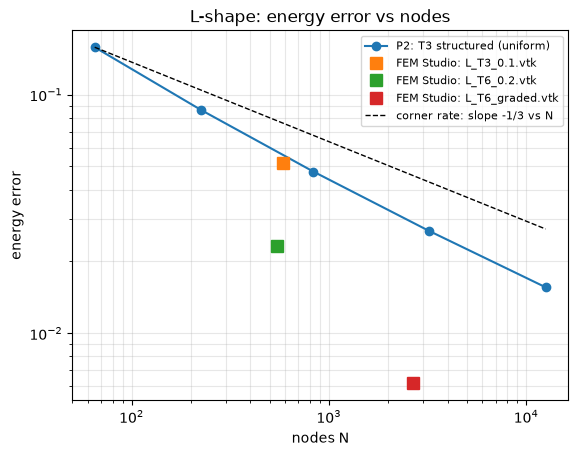

In [12]:
plt.loglog(N, e, 'o-', label='P2: T3 structured (uniform)')
for f, nodes, err in vtk_res:
    plt.loglog(nodes, err, 's', ms=8, label=f'FEM Studio: {f}')
plt.loglog(N, e[0] * (N / N[0])**(-1/3), 'k--', lw=1, label='corner rate: slope -1/3 vs N')
plt.xlabel('nodes N'); plt.ylabel('energy error'); plt.title('L-shape: energy error vs nodes')
plt.legend(fontsize=8); plt.grid(True, which='both', alpha=.3); plt.show()